# Credit Card Fraud Detection — EDA & Modeling

Exploratory data analysis and baseline models for the
[Kaggle Credit Card Fraud Detection dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).

The dataset contains 284,807 transactions made by European cardholders over two days,
of which only 492 (~0.17%) are fraudulent. Features `V1`–`V28` are PCA components;
`Time` and `Amount` are the only untransformed features.

**Contents**
1. Setup & data loading
2. Data overview
3. Target distribution
4. Transaction amount analysis
5. Time analysis
6. Correlation analysis
7. Feature engineering
8. Modeling: train/test split
9. Decision Tree — imbalanced vs. random undersampling
10. Random Forest — ROC-AUC vs. PR-AUC & feature importance
11. XGBoost with class weighting
12. Logistic Regression baseline
13. Model comparison

## 1. Setup & data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score,
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
)
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

CLASS_COLORS = ['#2ecc71', '#e74c3c']  # legit, fraud
RANDOM_STATE = 42

# Load dataset (download creditcard.csv from Kaggle into ../data/)
df_raw = pd.read_csv('../data/creditcard.csv')
df = df_raw.copy()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 2. Data overview

In [2]:
df.info()

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

Duplicate rows: 1081


## 3. Target distribution

Class
0    284315
1       492
Name: count, dtype: int64

Percentage:
Class
0   99.8273
1    0.1727
Name: proportion, dtype: float64


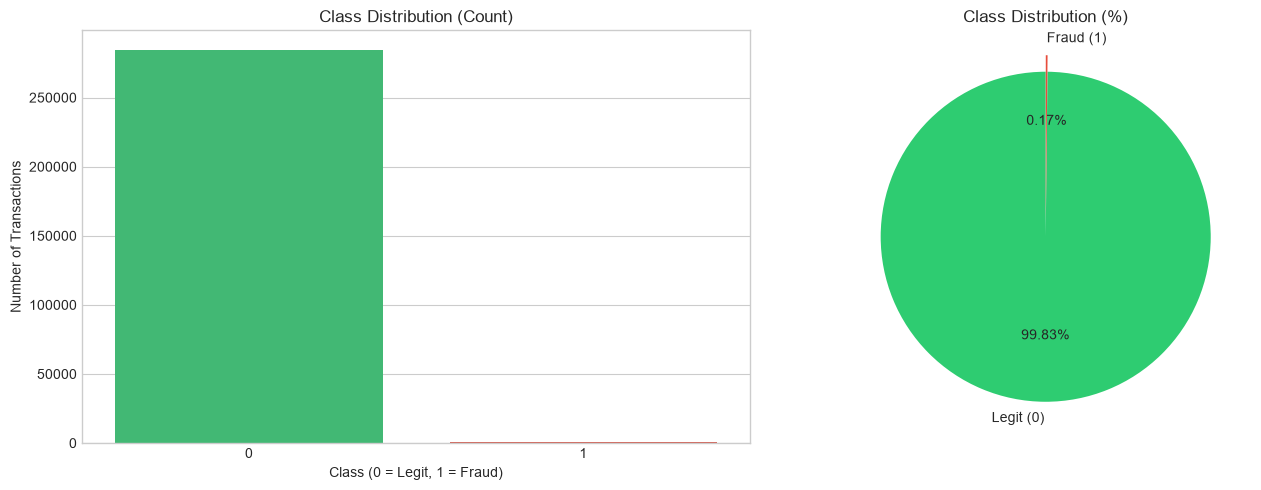

In [3]:
class_counts = df['Class'].value_counts()
class_percent = df['Class'].value_counts(normalize=True) * 100

print(class_counts)
print("\nPercentage:")
print(class_percent)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
sns.countplot(x='Class', hue='Class', data=df, ax=ax[0],
              palette=CLASS_COLORS, legend=False)
ax[0].set_title('Class Distribution (Count)')
ax[0].set_xlabel('Class (0 = Legit, 1 = Fraud)')
ax[0].set_ylabel('Number of Transactions')

# Pie chart
ax[1].pie(class_counts, labels=['Legit (0)', 'Fraud (1)'],
          autopct='%1.2f%%', colors=CLASS_COLORS,
          startangle=90, explode=(0, 0.1))
ax[1].set_title('Class Distribution (%)')

plt.tight_layout()
plt.show()

The dataset is **highly imbalanced**: only ~0.17% of transactions are fraud.
Accuracy is therefore a misleading metric — a model that predicts "legit" for
everything scores 99.83%. We focus on precision, recall and PR-AUC for the fraud class.

## 4. Transaction amount analysis

In [4]:
legit = df[df['Class'] == 0]
fraud = df[df['Class'] == 1]

print("Legit transactions:", len(legit))
print("Fraud transactions:", len(fraud))

print("\n=== Amount statistics by class ===")
print(df.groupby('Class')['Amount'].describe())

Legit transactions: 284315
Fraud transactions: 492

=== Amount statistics by class ===
            count     mean      std    min    25%     50%      75%        max
Class                                                                        
0     284315.0000  88.2910 250.1051 0.0000 5.6500 22.0000  77.0500 25691.1600
1        492.0000 122.2113 256.6833 0.0000 1.0000  9.2500 105.8900  2125.8700


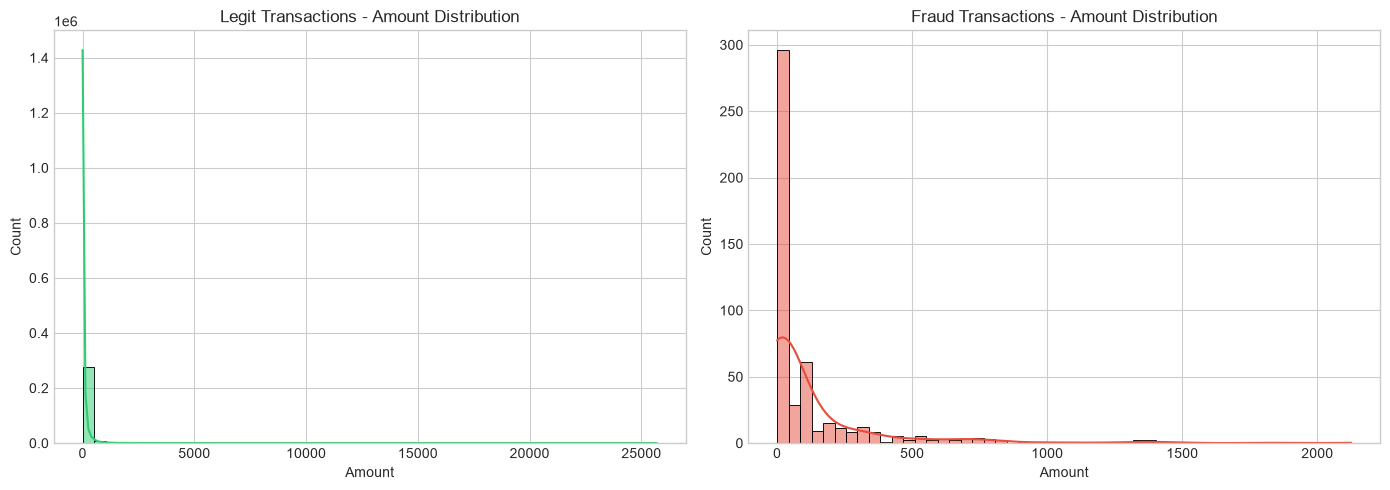

In [5]:
# Histogram of Amount (legit vs. fraud)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(legit['Amount'], bins=50, color=CLASS_COLORS[0], kde=True, ax=ax[0])
ax[0].set_title('Legit Transactions - Amount Distribution')
ax[0].set_xlabel('Amount')
ax[0].set_ylabel('Count')

sns.histplot(fraud['Amount'], bins=50, color=CLASS_COLORS[1], kde=True, ax=ax[1])
ax[1].set_title('Fraud Transactions - Amount Distribution')
ax[1].set_xlabel('Amount')
ax[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

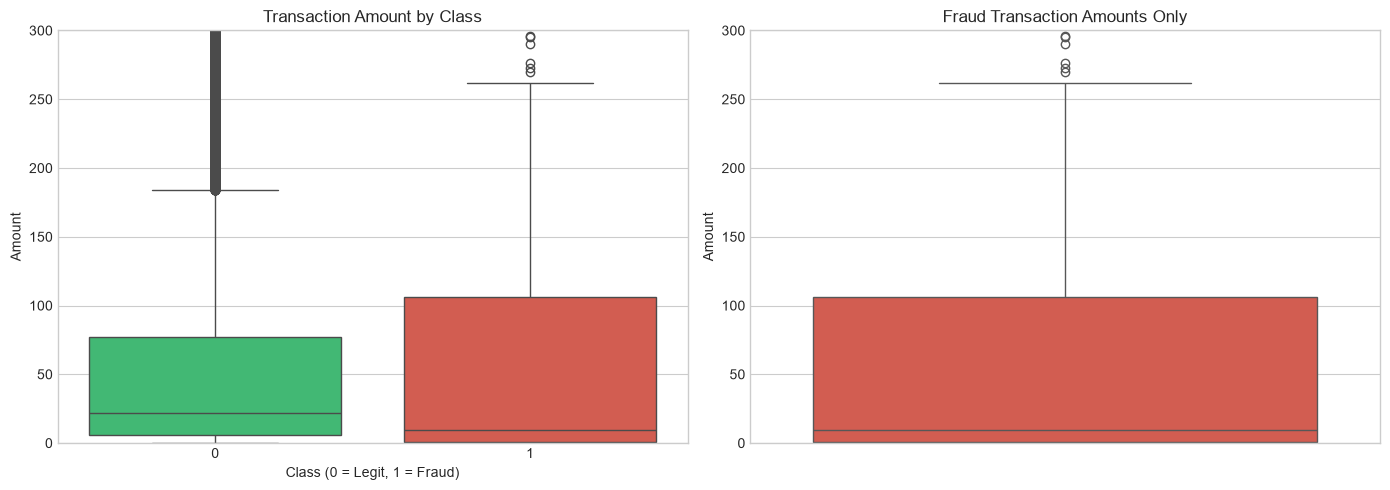

In [6]:
# Box plots: both classes side by side, and fraud only (zoomed to 0-300)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='Class', y='Amount', hue='Class', data=df, ax=ax[0],
            palette=CLASS_COLORS, legend=False)
ax[0].set_title('Transaction Amount by Class')
ax[0].set_xlabel('Class (0 = Legit, 1 = Fraud)')
ax[0].set_ylabel('Amount')
ax[0].set_ylim(0, 300)

sns.boxplot(y=fraud['Amount'], color=CLASS_COLORS[1], ax=ax[1])
ax[1].set_title('Fraud Transaction Amounts Only')
ax[1].set_ylabel('Amount')
ax[1].set_ylim(0, 300)

plt.tight_layout()
plt.show()

Fraudulent transactions have a **lower median amount** than legitimate ones
(≈9 vs. ≈22), but a higher mean because of a long right tail.
Both distributions are strongly right-skewed, so a log transform is useful.

## 5. Time analysis

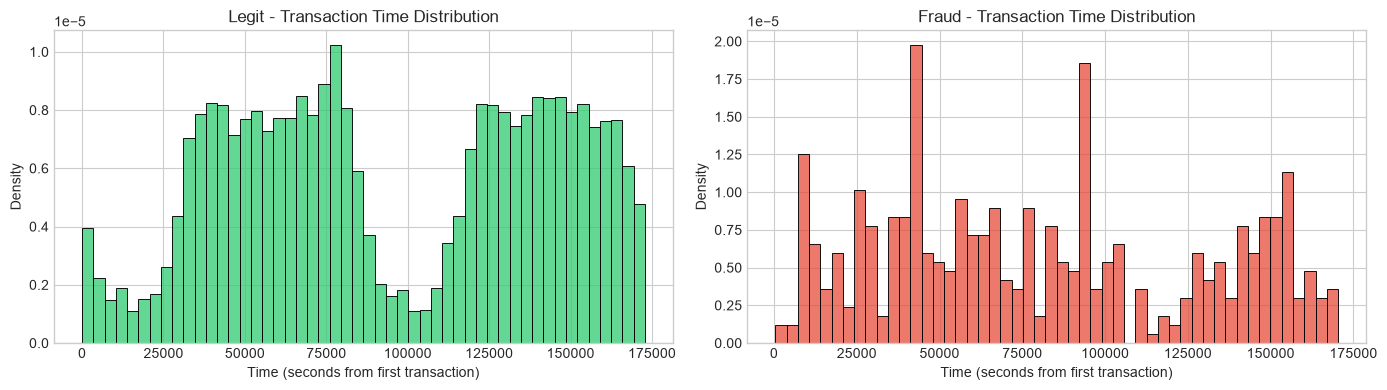

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(legit['Time'], bins=50, color=CLASS_COLORS[0], stat='density', ax=ax[0])
ax[0].set_title('Legit - Transaction Time Distribution')
ax[0].set_xlabel('Time (seconds from first transaction)')

sns.histplot(fraud['Time'], bins=50, color=CLASS_COLORS[1], stat='density', ax=ax[1])
ax[1].set_title('Fraud - Transaction Time Distribution')
ax[1].set_xlabel('Time (seconds from first transaction)')

plt.tight_layout()
plt.show()

Legitimate transactions show a clear day/night cycle over the two days.
Fraud is spread more evenly over time, so a larger share of fraud happens during
low-traffic (night) hours.

## 6. Correlation analysis

Top positive correlations with Class:
V11   0.1549
V4    0.1334
V2    0.0913
V21   0.0404
V19   0.0348
Name: Class, dtype: float64

Top negative correlations with Class:
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
Name: Class, dtype: float64


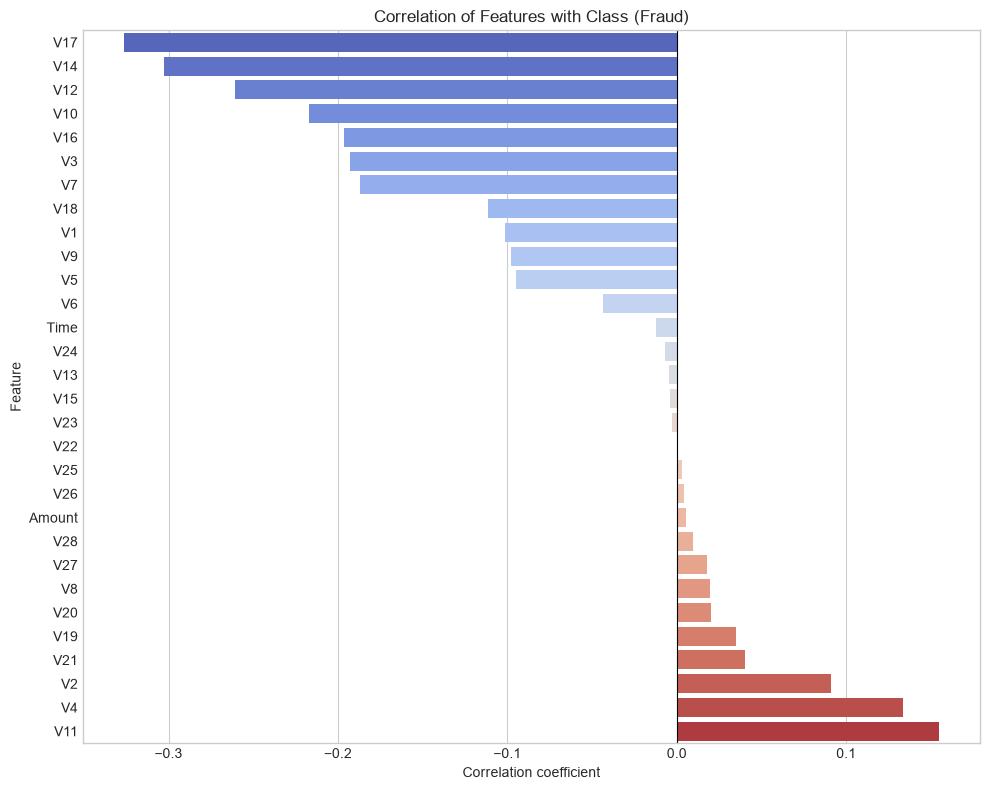

Features with |correlation| > 0.1:
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
V3    -0.1930
V7    -0.1873
V18   -0.1115
V1    -0.1013
V4     0.1334
V11    0.1549
Name: Class, dtype: float64


In [8]:
corr_with_class = df.corr()['Class'].drop('Class').sort_values()

print("Top positive correlations with Class:")
print(corr_with_class.tail(5)[::-1])
print("\nTop negative correlations with Class:")
print(corr_with_class.head(5))

# Bar view of correlations with Class
plt.figure(figsize=(10, 8))
sns.barplot(x=corr_with_class.values, y=corr_with_class.index,
            hue=corr_with_class.index, palette='coolwarm', legend=False)
plt.title('Correlation of Features with Class (Fraud)')
plt.xlabel('Correlation coefficient')
plt.ylabel('Feature')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

strong_features = corr_with_class[corr_with_class.abs() > 0.1]
print("Features with |correlation| > 0.1:")
print(strong_features)

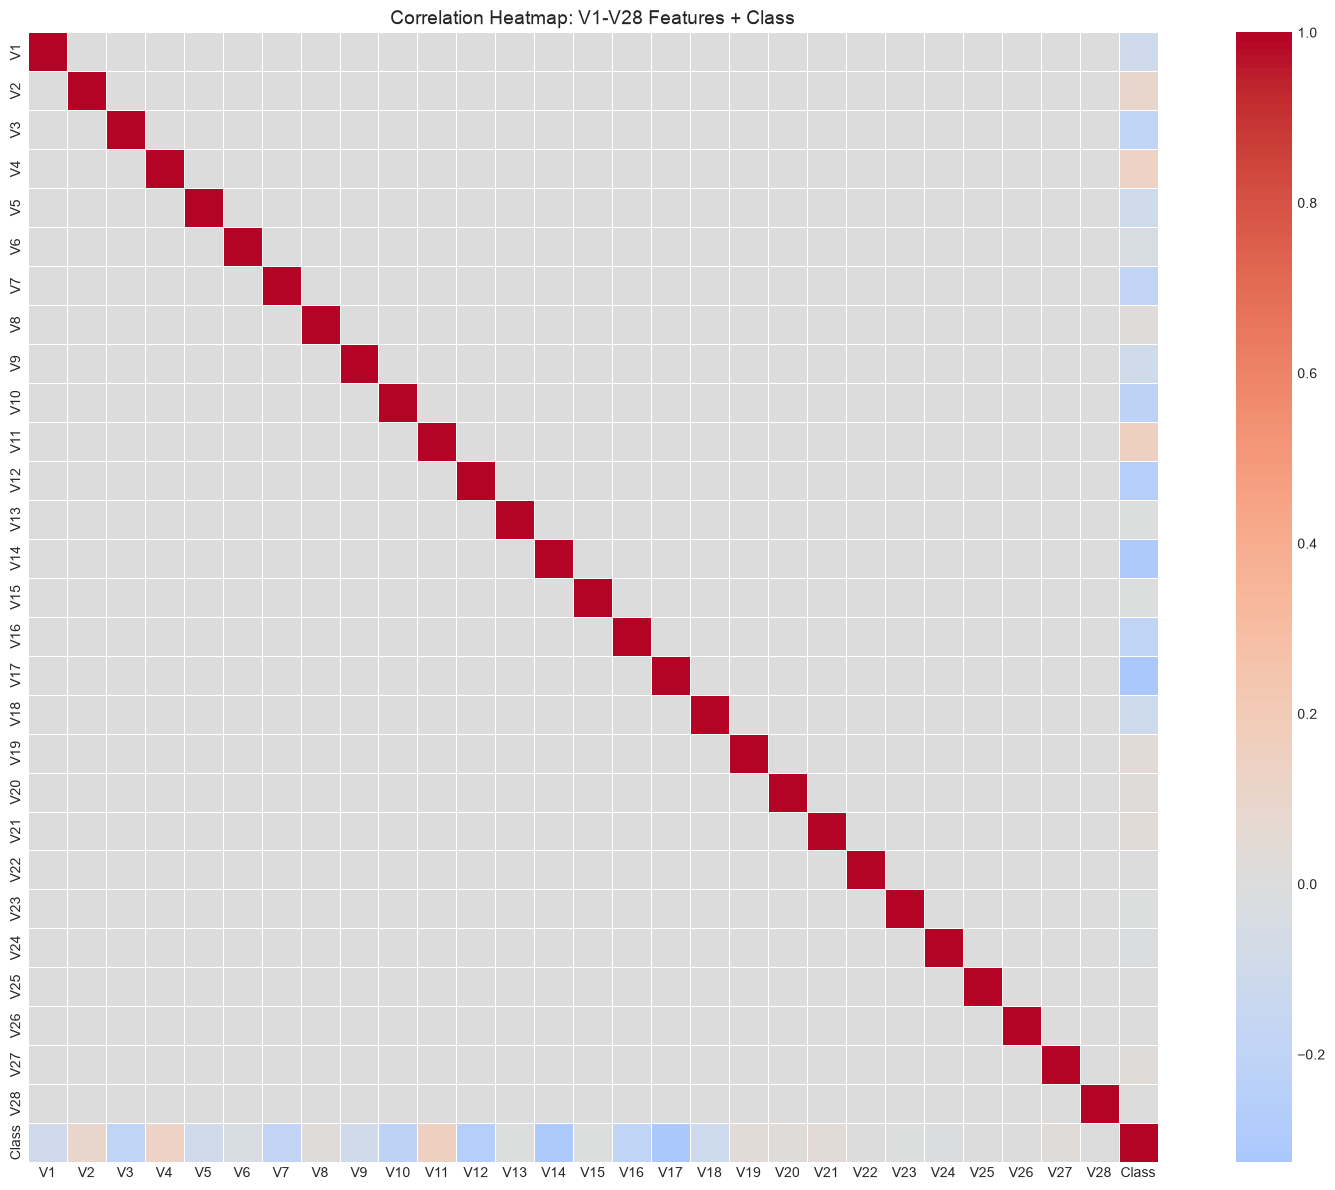

In [9]:
# Heatmap of V1-V28 + Class
v_features = [col for col in df.columns if col.startswith('V')] + ['Class']
corr_matrix = df[v_features].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False,
            linewidths=0.5, square=True)
plt.title('Correlation Heatmap: V1-V28 Features + Class', fontsize=14)
plt.tight_layout()
plt.show()

`V1`–`V28` are PCA components, so they are almost uncorrelated with each other.
The strongest (negative) correlations with fraud are **V17, V14, V12 and V10**;
the strongest positive ones are **V11 and V4**.

## 7. Feature engineering

Simple features derived from `Time` and `Amount`. The dataset has no user or card ID,
so the rolling features below are computed over the global transaction order —
this only demonstrates the idea. In a real project they would be computed per
card/user with `groupby('card_id')`.

These features are used for exploration only; the models below are trained on the
original columns.

In [10]:
df_fe = df.sort_values('Time').reset_index(drop=True)

# Approximate hour of day (the dataset does not say when the first transaction happened)
df_fe['Hour'] = (df_fe['Time'] // 3600) % 24

# Log of amount (reduces skewness)
df_fe['Amount_log'] = np.log1p(df_fe['Amount'])

# Time since previous transaction (in seconds)
df_fe['Time_diff'] = df_fe['Time'].diff()

# Rolling mean of amount over the last 5 transactions
df_fe['Amount_roll_mean_5'] = df_fe['Amount'].rolling(window=5, min_periods=1).mean()

# Deviation of current amount from the recent average
df_fe['Amount_diff_from_roll_mean'] = df_fe['Amount'] - df_fe['Amount_roll_mean_5']
df_fe['Amount_abs_diff'] = df_fe['Amount_diff_from_roll_mean'].abs()

# Z-score of amount
df_fe['Amount_zscore'] = (df_fe['Amount'] - df_fe['Amount'].mean()) / df_fe['Amount'].std()

new_features = ['Hour', 'Amount_log', 'Time_diff', 'Amount_roll_mean_5',
                'Amount_diff_from_roll_mean', 'Amount_abs_diff', 'Amount_zscore']

print("Dataset shape after feature engineering:", df_fe.shape)
df_fe[['Time', 'Amount'] + new_features].head(10)

Dataset shape after feature engineering: (284807, 38)


,Time,Amount,Hour,Amount_log,Time_diff,Amount_roll_mean_5,Amount_diff_from_roll_mean,Amount_abs_diff,Amount_zscore
0,0.0000,149.6200,0.0000,5.0148,NaN,149.6200,0.0000,0.0000,0.2450
1,0.0000,2.6900,0.0000,1.3056,0.0000,76.1550,-73.4650,73.4650,-0.3425
2,1.0000,378.6600,0.0000,5.9393,1.0000,176.9900,201.6700,201.6700,1.1607
3,1.0000,123.5000,0.0000,4.8243,0.0000,163.6175,-40.1175,40.1175,0.1405
4,2.0000,69.9900,0.0000,4.2625,1.0000,144.8920,-74.9020,74.9020,-0.0734
5,2.0000,3.6700,0.0000,1.5412,0.0000,115.7020,-112.0320,112.0320,-0.3386
6,4.0000,4.9900,0.0000,1.7901,2.0000,116.1620,-111.1720,111.1720,-0.3333
7,7.0000,40.8000,0.0000,3.7329,3.0000,48.5900,-7.7900,7.7900,-0.1901
8,7.0000,93.2000,0.0000,4.5454,0.0000,42.5300,50.6700,50.6700,0.0194
9,9.0000,3.6800,0.0000,1.5433,2.0000,29.2680,-25.5880,25.5880,-0.3385


Hour                         -0.0171
Amount_log                   -0.0083
Amount_diff_from_roll_mean    0.0036
Amount_roll_mean_5            0.0054
Amount_zscore                 0.0056
Amount_abs_diff               0.0065
Time_diff                     0.0190
Name: Class, dtype: float64


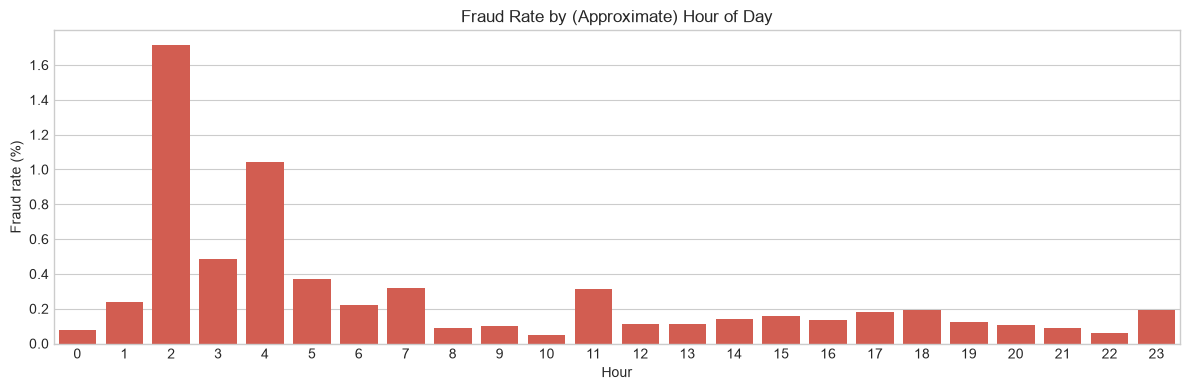

In [11]:
# Correlation of engineered features with Class
print(df_fe[new_features + ['Class']].corr()['Class'].drop('Class').sort_values())

# Fraud rate by hour of day
fraud_rate_by_hour = df_fe.groupby('Hour')['Class'].mean() * 100

plt.figure(figsize=(12, 4))
sns.barplot(x=fraud_rate_by_hour.index.astype(int), y=fraud_rate_by_hour.values,
            color=CLASS_COLORS[1])
plt.title('Fraud Rate by (Approximate) Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Fraud rate (%)')
plt.tight_layout()
plt.show()

## 8. Modeling: train/test split

All models use the **same stratified 80/20 split**, so their results are directly
comparable. Stratification keeps the fraud ratio identical in both sets.

In [12]:
X = df_raw.drop('Class', axis=1)
y = df_raw['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train distribution:", Counter(y_train))
print("Test distribution: ", Counter(y_test))

# Collect metrics of every model for the final comparison
results = {}

def evaluate(name, y_pred, y_proba):
    """Print classification metrics and store ROC-AUC / PR-AUC."""
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, digits=3))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)
    print(f"ROC-AUC: {roc_auc:.4f}   PR-AUC: {pr_auc:.4f}\n")
    results[name] = {
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'Precision (fraud)': precision_score(y_test, y_pred),
        'Recall (fraud)': recall_score(y_test, y_pred),
    }

Train distribution: Counter({0: 227451, 1: 394})
Test distribution:  Counter({0: 56864, 1: 98})


## 9. Decision Tree — imbalanced vs. random undersampling

Resampling is applied **only to the training set**, after the split, so that the
test set keeps the real class distribution.

In [13]:
# Decision Tree on the original (imbalanced) data
dt_imbalanced = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_imbalanced.fit(X_train, y_train)
evaluate('Decision Tree (imbalanced)',
         dt_imbalanced.predict(X_test), dt_imbalanced.predict_proba(X_test)[:, 1])

# Random undersampling: randomly drop majority-class samples until classes are balanced
rus = RandomUnderSampler(random_state=RANDOM_STATE)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)
print("After random undersampling:", Counter(y_train_res), "\n")

dt_under = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_under.fit(X_train_res, y_train_res)
evaluate('Decision Tree (undersampled)',
         dt_under.predict(X_test), dt_under.predict_proba(X_test)[:, 1])

=== Decision Tree (imbalanced) ===
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56864
           1      0.753     0.745     0.749        98

    accuracy                          0.999     56962
   macro avg      0.876     0.872     0.874     56962
weighted avg      0.999     0.999     0.999     56962

Confusion matrix:
[[56840    24]
 [   25    73]]
ROC-AUC: 0.8722   PR-AUC: 0.5610

After random undersampling: Counter({0: 394, 1: 394}) 

=== Decision Tree (undersampled) ===
              precision    recall  f1-score   support

           0      1.000     0.903     0.949     56864
           1      0.016     0.908     0.031        98

    accuracy                          0.903     56962
   macro avg      0.508     0.906     0.490     56962
weighted avg      0.998     0.903     0.948     56962

Confusion matrix:
[[51364  5500]
 [    9    89]]
ROC-AUC: 0.9057   PR-AUC: 0.0146



Undersampling raises recall for fraud but sharply lowers precision: the model now
flags many legitimate transactions as fraud, because it was trained on only ~800 samples.

## 10. Random Forest — ROC-AUC vs. PR-AUC & feature importance

In [14]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,          # limit depth to reduce overfitting
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

rf_proba = rf.predict_proba(X_test)[:, 1]
evaluate('Random Forest', rf.predict(X_test), rf_proba)

=== Random Forest ===
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56864
           1      0.941     0.816     0.874        98

    accuracy                          1.000     56962
   macro avg      0.970     0.908     0.937     56962
weighted avg      1.000     1.000     1.000     56962

Confusion matrix:
[[56859     5]
 [   18    80]]
ROC-AUC: 0.9743   PR-AUC: 0.8640



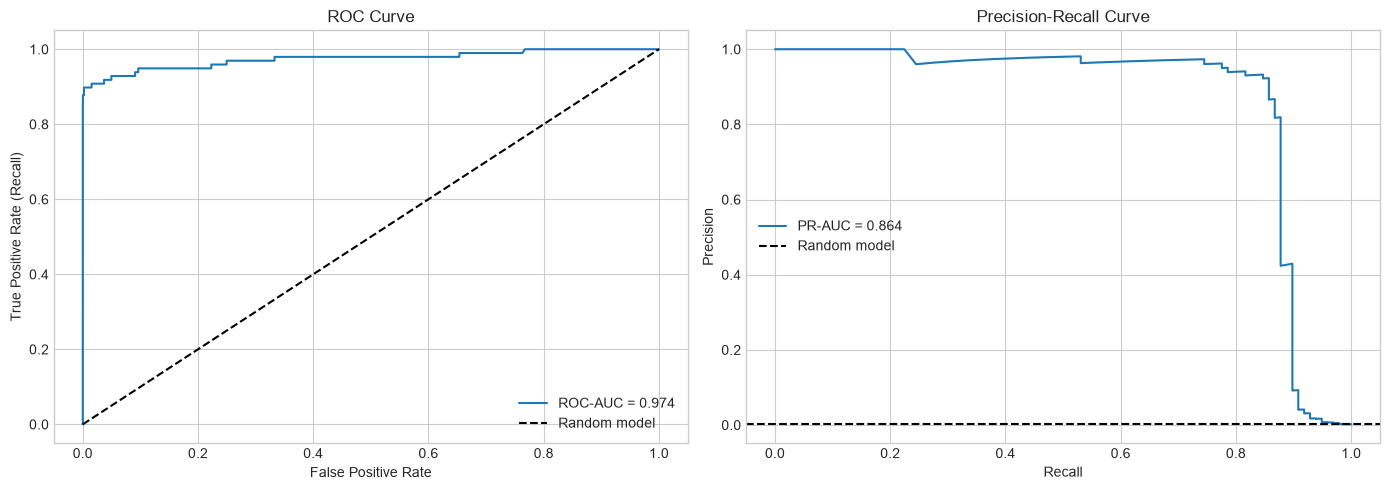

In [15]:
# ROC curve vs. Precision-Recall curve
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

fpr, tpr, _ = roc_curve(y_test, rf_proba)
ax[0].plot(fpr, tpr, label=f"ROC-AUC = {results['Random Forest']['ROC-AUC']:.3f}")
ax[0].plot([0, 1], [0, 1], 'k--', label='Random model')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate (Recall)')
ax[0].set_title('ROC Curve')
ax[0].legend()

precision, recall, _ = precision_recall_curve(y_test, rf_proba)
ax[1].plot(recall, precision, label=f"PR-AUC = {results['Random Forest']['PR-AUC']:.3f}")
ax[1].axhline(y_test.mean(), color='k', linestyle='--', label='Random model')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve')
ax[1].legend()

plt.tight_layout()
plt.show()

ROC-AUC looks excellent for almost any reasonable model on imbalanced data, because
the huge number of true negatives keeps the false positive rate low.
**PR-AUC is the more informative metric here** — a random model scores only ~0.0017.

=== Top 10 most important features ===
   feature  importance
17     V17      0.1898
12     V12      0.1510
14     V14      0.1482
16     V16      0.0812
10     V10      0.0798
11     V11      0.0464
9       V9      0.0370
18     V18      0.0313
4       V4      0.0267
7       V7      0.0221


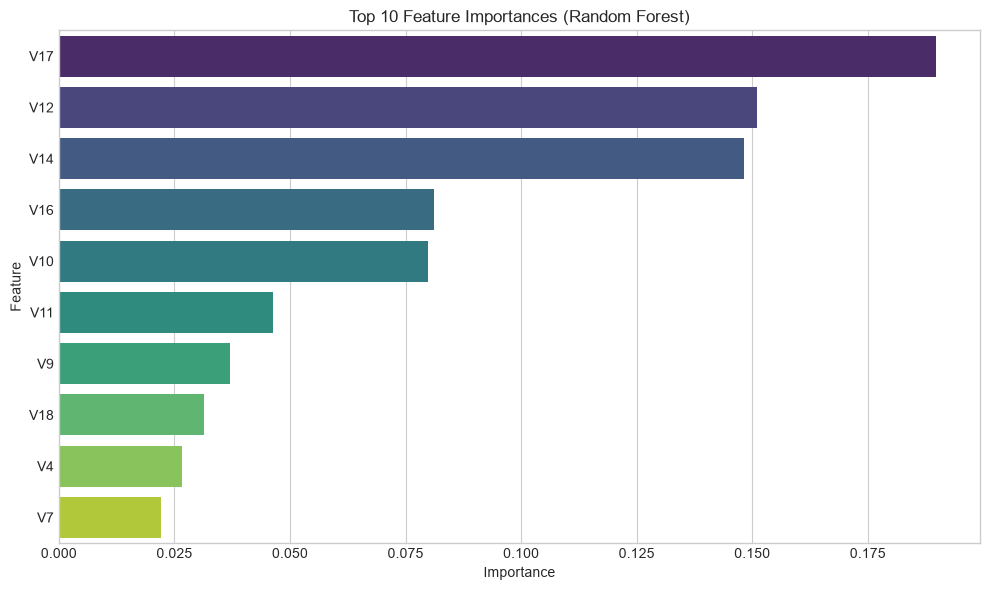

In [16]:
# Feature importance
importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_,
}).sort_values('importance', ascending=False)

print("=== Top 10 most important features ===")
print(importance_df.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(10), x='importance', y='feature',
            hue='feature', palette='viridis', legend=False)
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 11. XGBoost with class weighting

Instead of resampling, `scale_pos_weight = n_legit / n_fraud` makes each fraud sample
count as much as ~577 legitimate ones in the loss function.

In [17]:
n_legit = (y_train == 0).sum()
n_fraud = (y_train == 1).sum()
scale_pos_weight = n_legit / n_fraud
print("scale_pos_weight:", round(scale_pos_weight, 2), "\n")

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric='aucpr',   # PR-AUC is the relevant metric for imbalanced data
)
xgb.fit(X_train, y_train)

evaluate('XGBoost (weighted)', xgb.predict(X_test), xgb.predict_proba(X_test)[:, 1])

scale_pos_weight: 577.29 



=== XGBoost (weighted) ===
              precision    recall  f1-score   support

           0      1.000     0.999     0.999     56864
           1      0.500     0.847     0.629        98

    accuracy                          0.998     56962
   macro avg      0.750     0.923     0.814     56962
weighted avg      0.999     0.998     0.999     56962

Confusion matrix:
[[56781    83]
 [   15    83]]
ROC-AUC: 0.9734   PR-AUC: 0.8384



## 12. Logistic Regression baseline

`Time` and `Amount` are scaled (fit on train only, to avoid data leakage);
`V1`–`V28` are already PCA-scaled. `class_weight='balanced'` compensates for imbalance.

In [18]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()
scale_cols = ['Amount', 'Time']
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

log_reg = LogisticRegression(class_weight='balanced', max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

evaluate('Logistic Regression (balanced)',
         log_reg.predict(X_test_scaled), log_reg.predict_proba(X_test_scaled)[:, 1])

=== Logistic Regression (balanced) ===
              precision    recall  f1-score   support

           0      1.000     0.976     0.988     56864
           1      0.061     0.918     0.114        98

    accuracy                          0.976     56962
   macro avg      0.530     0.947     0.551     56962
weighted avg      0.998     0.976     0.986     56962

Confusion matrix:
[[55478  1386]
 [    8    90]]
ROC-AUC: 0.9722   PR-AUC: 0.7159



## 13. Model comparison

In [19]:
results_df = pd.DataFrame(results).T.sort_values('PR-AUC', ascending=False)
results_df

,ROC-AUC,PR-AUC,Precision (fraud),Recall (fraud)
Random Forest,0.9743,0.8640,0.9412,0.8163
XGBoost (weighted),0.9734,0.8384,0.5000,0.8469
Logistic Regression (balanced),0.9722,0.7159,0.0610,0.9184
Decision Tree (imbalanced),0.8722,0.5610,0.7526,0.7449
Decision Tree (undersampled),0.9057,0.0146,0.0159,0.9082


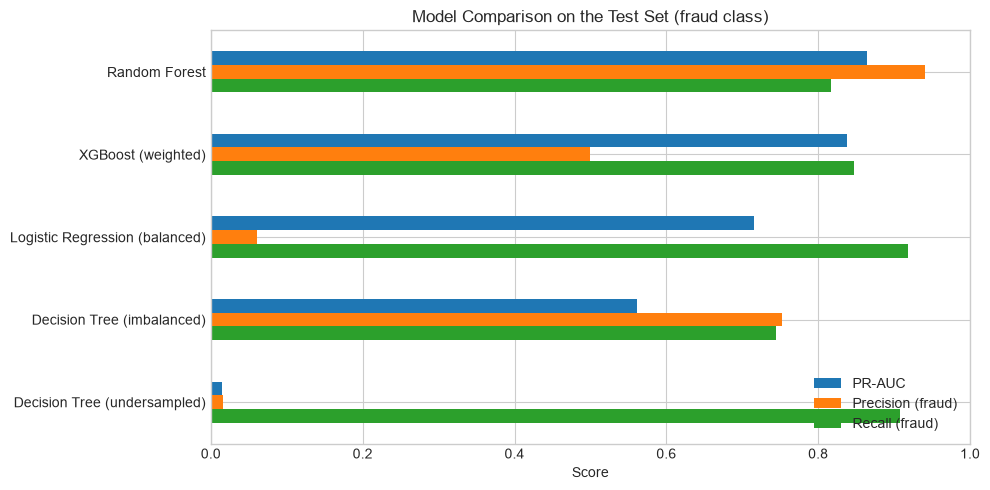

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
results_df[['PR-AUC', 'Precision (fraud)', 'Recall (fraud)']].plot.barh(ax=ax)
ax.set_title('Model Comparison on the Test Set (fraud class)')
ax.set_xlabel('Score')
ax.set_xlim(0, 1)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Conclusions

- The data is extremely imbalanced (0.17% fraud), so accuracy and ROC-AUC are
  misleading; PR-AUC, precision and recall on the fraud class are what matter.
- Fraud transactions have a lower median amount and are relatively more frequent
  during night hours.
- V17, V14, V12 and V10 are the most informative features (highest correlation and
  highest Random Forest importance).
- Tree ensembles (Random Forest, XGBoost) clearly outperform a single Decision Tree and
  Logistic Regression in PR-AUC.
- Class weighting / undersampling trade precision for recall. The decision threshold
  can be tuned on the predicted probabilities to pick the right balance for the business.